# Vision OCR, VLM и перевод текста на изображениях

Многие данные приходят к нам не в виде аккуратного текста, а в виде изображений: слайды, фотографии объявлений, скриншоты интерфейсов, документы, ценники, таблицы. Для таких задач полезны два подхода:

* **OCR** — специализированное распознавание текста на изображении. OCR возвращает текст и координаты блоков, строк и слов.
* **VLM** — мультимодальная языковая модель. Она может не только прочитать текст, но и объяснить, что происходит на изображении, как связаны элементы, где диаграмма или подпись.

В этом ноутбуке мы:

1. Распознаем текст на `BDCC-0.jpg` через Vision OCR.
2. Попросим Qwen3.6 прочитать и объяснить то же изображение как VLM.
3. Переведём распознанный текст через Yandex Translate.
4. Возьмём `photo.png`, найдём текстовые фрагменты, переведём их на русский и наложим перевод поверх исходной картинки.

Полезные ссылки:

* [Vision OCR](https://yandex.cloud/ru/docs/vision/concepts/ocr/)
* [Vision OCR API recognizeText](https://yandex.cloud/en/docs/vision/ocr/api-ref/TextRecognition/recognize)
* [Yandex Translate API](https://yandex.cloud/ru/docs/translate/)
* [Мультимодальные модели в AI Studio](https://yandex.cloud/ru/docs/ai-studio/)


In [ ]:
%pip install --quiet openai python-dotenv requests pillow


> **ВНИМАНИЕ**: После установки библиотек рекомендуется перезапустить Kernel ноутбука.

## Авторизация

Используем тот же стиль авторизации, что и в других разделах курса: `.env` содержит `folder_id` и `api_key`.


In [ ]:
!curl -o .env {{url_of_dotenv_file}}


In [1]:
import base64
import os
import textwrap
import io
from pathlib import Path

import requests
from dotenv import load_dotenv
from IPython.display import Image as IPImage
from IPython.display import Markdown, display
from openai import OpenAI
from PIL import Image, ImageDraw, ImageFont

load_dotenv()

folder_id = os.environ["folder_id"]
api_key = os.environ["api_key"]

vision_model = f"gpt://{folder_id}/qwen3.6-35b-a3b"

client = OpenAI(
    base_url="https://ai.api.cloud.yandex.net/v1",
    api_key=api_key,
    project=folder_id,
)

def printx(string):
    display(Markdown(string))

data_dir = Path.cwd() / "data"

print(f"✅ Авторизация настроена (folder_id: {folder_id[:8]}...)")


✅ Авторизация настроена (folder_id: b1gbicod...)


## Часть 1. OCR: распознаём текст на изображении

Сервис Vision OCR предназначен для распознавания печатного или рукописного текста на изображении. Для его вызова будем использовать REST API напрямую, поскольку в SDK соответствующие функции пока отсутствуют. 

Для вызова REST API необходимо передать заголовок авторизации такого вида:

In [2]:
auth_headers = {"Authorization": f"Api-Key {api_key}"}

def call_api(url,body):
    response = requests.post(
        url,
        headers=auth_headers,
        json=body,
        timeout=120
    )
    response.raise_for_status()
    return response.json()

Для вызова сервиса ему необходимо передать изображение в кодировке base64. Кроме того, можно передать используемую [модель распознавания](https://aistudio.yandex.ru/docs/ru/vision/concepts/ocr/#models):
* `page` - обычно используется для страницы или слайда. Она ищет блоки, строки и слова, а также возвращает координаты. Эти координаты могут пригодиться, если мы например захотим накладывать перевод надписей обратно на изображение
* `handwritten` используется для рукописного текста
* `table` может использоваться для распознавания таблиц
* `math-markdown` позволяет распознавать богатое форматирование с математическими формулами, которые представляются в формате LaTeX

Есть также другие модели, а также существуют отдельные модели для распознавания разных стандартных документов.


In [3]:
ocr_url = "https://ocr.api.cloud.yandex.net/ocr/v1/recognizeText"

def image_to_base64(image):
    image = image.convert("RGB")
    buffer = io.BytesIO()
    image.save(buffer, format='png')
    image_bytes = buffer.getvalue()
    return base64.b64encode(image_bytes).decode("utf-8")

def ocr_recognize(img, language_codes=None, model_name="page"):
    body = {
        "mimeType": "image/png",
        "languageCodes": language_codes or ["*"],
        "model": model_name,
        "content": image_to_base64(img)
    }
    return call_api(ocr_url,body)

Рассмотрим страницу из статьи:

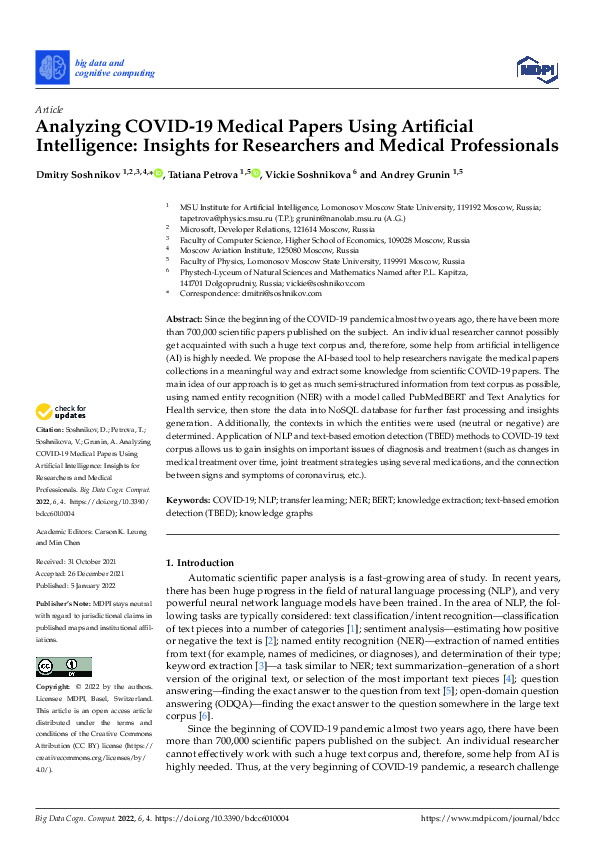

In [4]:
page_path = data_dir / "BDCC-0.jpg"
IPImage(filename=str(page_path))


Теперь распознаем её:

In [5]:
img = Image.open(page_path)
ocr = ocr_recognize(img)
ocr_text = ocr['result']['textAnnotation']['fullText']

printx(ocr_text)

big data and
cognitive computing
Article
Analyzing COVID-19 Medical Papers Using Artificial
Intelligence: Insights for Researchers and Medical Professionals
Dmitry Sosh nikov 1,2,3,4,4,9, Tatiana Petrova 1,50, Vickie Soshnikova 6 and Andrey Grunin 1,5
1 MSU Institute for Artificial Intelligence, Lomonosov Moscow State University, 119192 Moscow, Russia;
tapetrova@physics.msu.ru (T.P.); grunin@nanolab.msu.ru (A.G.)
2 Microsoft, Developer Relations, 121614 Moscow, Russia
3 Faculty of Computer Science, Higher School of Economics, 109028 Moscow, Russia
4 Moscow Aviation Institute, 125080 Moscow, Russia
5 Faculty of Physics, Lomonosov Moscow State University, 119991 Moscow, Russia
6 Phystech-Lyceum of Natural Sciences and Mathematics Named after P.I. Kapitza,
141701 Dolgoprudniy, Russia; vickie@soshnikov.com
*
Correspondence: dmitri@soshnikov.com
check for
updates
Citation: Soshnikov, D.; Petrova, T.;
Soshnikova, V.; Granin, A. Analyzing
COVID-19 Medical Papers Using
Artificial Intelligence: Insights for
Researchers and Medical
Professionals. Big Data Cogn Comput.
2022,6,4. https://dol.org/10.3390/
bdcc6010004
Abstract: Since the beginning of the COVID-19 pandemicalmost two years ago, there have been more
than 700,000 scientific papers published on the subject. An individual researcher cannot possibly
get acquainted with such a huge text corpus and, therefore, some help from artificial intelligence
(AI) is highly needed. We propose the AI-based tool to help researchers navigate the medical papers
collections in a meaningful way and extract some knowledge from scientific COVID-19 papers. The
main idea of our approach is to get as much semi-structured information from text corpus as possible,
using named entity recognition (NER) with a model called PubMedBERT and Text Analytics for
Health service, then store the data into NoSQL database for further fast processing and insights
generation. Additionally, the contexts in which the entities were used (neutral or negative) are
determined. Application of NLP and text-based emotion detection (TBED) methods to COVID-19 text
corpus allows us to gain insights on important issues of diagnosis and treatment (such as changes in
medical treatment over time, joint treatment strategies using several medications, and the connection
between signs and symptoms of coronavirus, etc.).
Keywords: COVID-19; NLP; transfer learning; NER; BERT; knowledge extraction; text-based emotion
detection (TBED); knowledge graphs
Academic Editors: Carson K. Leung
and Min Chen
Received: 3L October 2021
Accepted: 26 December 2021
Published: 5 January 2022
1. Introduction
Publisher's Note: MDPI stays neutral
with regard to jurisdic tional claims in
published maps and institutional affil-
of
iations.
Copyright © 2022 by the authors.
Licensee MDPI, Basel, Switzerland.
This article is an open access article
distributed under the terms and
conditions of the Creative Commons
Attribution (CC BY) license (https://
cm ativecommons.org/licenses/by/
4.0/).
Automatic scientific paper analysis is a fast-growing area of study. In recent years,
there has been huge progress in the field of natural language processing (NLP), and very
powerful neural network language models have been trained. In the area of NLP, the fol-
lowing tasks are typically considered: text classification/intent recognition—classification
text pieces into a number of categories [1]; sentiment analysis—estimating how positive
or negative the text is [2]; named entity recognition (NER)—extraction of named entities
from text (for example, names of medicines, or diagnoses), and determination of their type;
keyword extraction [3]—a task similar to NER; text summarization—generation of a short
version of the original text, or selection of the most important text pieces [4]; question
answering—finding the exact answer to the question from text [5]; open-domain question
answering (ODQA)—finding the exact answer to the question somewhere in the large text
corpus [6].
Since the beginning of COVID-19 pandemic almost two years ago, there have been
more than 700,000 scientific papers published on the subject. An individual researcher
cannot effectively work with such a huge text corpus and, therefore, some help from AI is
highly needed. Thus, at the very beginning of COVID-19 pandemic, a research challenge
Big Data Cogn. Comput. 2022, 6, 4. https://doi.org/10.3390/bdcc6010004
https://www.mdpi.com/journal/bdcc


## Часть 2. VLM: читаем и объясняем изображение

OCR хорош, когда нам нужен текст и координаты. Но если на слайде есть диаграмма, схема или важная визуальная структура, специализированный OCR может вернуть только подписи. Мультимодальная модель может описать изображение целиком: что на нём находится, какие есть блоки, как устроена композиция и что важно для понимания.


In [6]:
def image_to_data_url(img):
    encoded = image_to_base64(img)
    return f"data:image/png;base64,{encoded}"

vlm_prompt = """Распознай текст на изображении и кратко объясни, что изображено.
Верни ответ по-русски в Markdown:
1. Распознанный текст.
2. Описание изображения.
3. Что может быть важно для студента, который изучает этот материал.
"""

vlm_response = client.responses.create(
    model=vision_model,
    input=[
        {
            "role": "user",
            "content": [
                {"type": "input_text", "text": vlm_prompt},
                {"type": "input_image", "image_url": image_to_data_url(img), "detail": "auto"},
            ],
        }
    ],
)

printx(vlm_response.output_text)




1. **Распознанный текст:**

   **Заголовок:** Analyzing COVID-19 Medical Papers Using Artificial Intelligence: Insights for Researchers and Medical Professionals
   **Авторы:** Dmitry Soshnikov, Tatiana Petrova, Vickie Soshnikova и Andrey Grunin
   **Журнал:** Big Data and Cognitive Computing (MDPI)
   **Аннотация (Abstract excerpt):** "Since the beginning of the COVID-19 pandemic almost two years ago, there have been more than 700,000 scientific papers published on the subject. An individual researcher cannot possibly get acquainted with such a huge text corpus..."
   **Ключевые слова (Keywords):** COVID-19; NLP; transfer learning; NER; BERT; knowledge extraction; text-based emotion detection (TBED); knowledge graphs
   **Введение (Introduction excerpt):** "Automatic scientific paper analysis is a fast-growing area of study... powerful neural language models have been trained."

2. **Описание изображения:**

   На изображении представлена первая страница академической научной статьи, опубликованной в международном журнале *Big Data and Cognitive Computing* (издательство MDPI).
   
   Документ структурирован стандартным образом для научных публикаций:
   *   Вверху указано название журнала и логотип MDPI.
   *   Даны заголовок исследования, имена четырех авторов (из России и Швейцарии) и их научные связи (аффилиации).
   *   Присутствует блок **Abstract** (аннотация), описывающий проблему огромного объема медицинских данных о COVID-19 и предлагающий решение с использованием AI (искусственного интеллекта).
   *   Есть раздел **Keywords** (ключевые слова).
   *   Начинается раздел **1. Introduction** (Введение), где Описываются достижения в области Natural Language Processing (NLP).

3. **Что может быть важно для студента, который изучает этот материал:**

   *   **Практическое применение NLP:** Статья демонстрирует, как технологии обработки естественного языка (NLP), такие как распознавание именованных сущностей (NER) и тематическое моделирование, используются в реальной жизни (в медицине) для анализа гигантских массивов данных.
   *   **Конкретные технологии:** Для студентов IT-специальностей важно увидеть упоминание конкретных инструментов и подходов: модель *PubmedBERT*, базы данных *NoSQL*, методы *transfer learning* и создание *knowledge graphs* (графов знаний).
   *   **Навык работы с "Big Data":** Пример решения проблемы, когда человек физически не может прочитать 700 000 статей, и роль AI в автоматизации этого процесса.
   *   **Структура научной работы:** Студентам-гуманитариям или будущим ученым полезно посмотреть на эталонную структуру статьи: от постановки проблемы через аннотацию к введению.

## Часть 3. Переводим распознанный текст

Для перевода текста на другой язык, можно использовать LLM, либо же специальный сервис Yandex Translate. Последнее избавляет нас от необходимости заботиться о промпт-инъекциях. Сервис перевода удобно использовать после OCR: сначала извлекаем текст, затем переводим его на нужный язык.

In [7]:
translate_url = "https://translate.api.cloud.yandex.net/translate/v2/translate"

def translate_texts(texts, target_language="ru", source_language=None):
    body = {
        "folderId": folder_id,
        "texts": texts,
        "targetLanguageCode": target_language,
        "format": "PLAIN_TEXT",
    }
    if source_language:
        body["sourceLanguageCode"] = source_language
    data = call_api(translate_url, body)
    return [item["text"] for item in data["translations"]]

translated_text = translate_texts([ocr_text], target_language="ru")[0]
printx(translated_text)


большие данные и
когнитивные вычисления
Статья
Анализ медицинских документов о COVID-19 с использованием искусственного интеллекта
Аналитические материалы для исследователей и медицинских работников
Дмитрий Сошников 1,2,3,4,4,9, Татьяна Петрова 1,50, Вики Сошникова 6 и Андрей Грунин 1,5
1 Институт искусственного интеллекта МГУ им. М.В. Ломоносова, 119192, Москва, Россия;
tapetrova@physics.msu.ru (Т.П.); grunin@nanolab.msu.ru (А.Г.)
2 Microsoft, отдел по связям с разработчиками, 121614, Москва, Россия
3 Факультет компьютерных наук, Высшая школа экономики, 109028 Москва, Россия
4 Московский авиационный институт, 125080 Москва, Россия
5 Физический факультет, Московский государственный университет имени М.В. Ломоносова, 119991 Москва, Россия
Физтех-лицей естественных наук и математики им. П.И. Капицы, 6
, Долгопрудный, Россия, 141701; vickie@soshnikov.com
*
Для корреспонденции: dmitri@soshnikov.com
следите за
обновлениями
Образец цитирования: Сошников Д.; Петрова Т.;
Сошникова В.; Гранин А. Анализируя
Медицинские документы, подтверждающие COVID-19, с использованием
Искусственный интеллект: идеи для
Исследователи и медицинские работники
Профессионалы. Познание больших данных.
2022,6,4. https://dol.org/10.3390/
bdcc6010004
Аннотация: С начала пандемии COVID-19 почти два года назад было
опубликовано более 700 000 научных работ на эту тему. Отдельный исследователь вряд ли
сможет ознакомиться с таким огромным текстовым массивом, и поэтому крайне необходима некоторая помощь искусственного интеллекта
(ИИ). Мы предлагаем инструмент на основе искусственного интеллекта, который поможет исследователям
осмысленно ориентироваться в коллекциях медицинских работ и извлекать некоторые знания из научных статей о COVID-19. 
Основная идея нашего подхода заключается в том, чтобы получить как можно больше полуструктурированной информации из текстового корпуса,
используя распознавание именованных объектов (NER) с моделью под названием PubMedBERT и текстовую аналитику для
Службы здравоохранения, затем сохраните данные в базе данных NoSQL для дальнейшей быстрой обработки и получения аналитических
данных. Кроме того, определяются контексты, в которых использовались объекты (нейтральные или негативные)
. Применение методов НЛП и распознавания эмоций на основе текста (TBED) к текстовому
корпусу COVID-19 позволяет нам получить представление о важных вопросах диагностики и лечения (таких как изменения в
лечении с течением времени, стратегии совместного лечения с использованием нескольких лекарств, связь
между признаками и симптомами коронавируса и т.д.).).
Ключевые слова: COVID-19; НЛП; трансферное обучение; NER; BERT; извлечение знаний; распознавание эмоций на основе текста
(TBED); графы знаний
Научные редакторы: Карсон К. Люнг
и Мин Чен
Поступила в редакцию 3 октября 2021 г.
Принято: 26 декабря 2021 г.
Опубликовано: 5 января 2022 г.
1. введение
Примечание издателя: MDPI сохраняет нейтралитет
в отношении юридических претензий, содержащихся в
опубликованных картах и документах
учреждений
.
Авторское право © 2022 принадлежит авторам.
Лицензиат MDPI, Базель, Швейцария.
Эта статья находится в открытом доступе
и распространяется на
условиях Creative Commons
Лицензия на использование авторских прав (CC BY) (https://
cm ativecommons.org/licenses/by/
4.0/).
Автоматический анализ научных статей - быстро развивающаяся область исследований. В последние годы
достигнут огромный прогресс в области обработки естественного языка (NLP), и
были обучены очень мощные языковые модели с использованием нейронных сетей. В области НЛП
обычно рассматриваются следующие задачи: классификация текста/распознавание намерений - классификация
фрагментов текста по нескольким категориям [1]; анализ настроений — оценка того, насколько позитивным
или негативным является текст [2]; распознавание именованных объектов (NER) — извлечение именованных объектов
из текста. текст (например, названия лекарств или диагнозы) и определение их типа;
извлечение ключевых слов [3] — задача, аналогичная NER; обобщение текста — создание краткой
версии исходного текста или выбор наиболее важных фрагментов текста [4];
ответы на вопросы — поиск точного ответа на вопрос из текста [5]; ответы на вопросы в открытой области
(ODQA) — поиск точного ответа на вопрос где-нибудь в большом
корпусе текстов [6].
С начала пандемии COVID-19, которая началась почти два года назад, было
опубликовано более 700 000 научных работ на эту тему. Отдельный исследователь
не может эффективно работать с таким огромным массивом текстов, и поэтому
крайне необходима помощь искусственного интеллекта. Таким образом, в самом начале пандемии COVID-19 возникла исследовательская задача
Познание больших данных. Вычисление. 2022, 6, 4. https://doi.org/10.3390/bdcc6010004
https://www.mdpi.com/journal/bdcc


## Часть 4. Переводим текстовые фрагменты на фотографии

Теперь попробуем сделать кое-что более интересное. Предположим, у нас есть вот такая фотография с надписями:

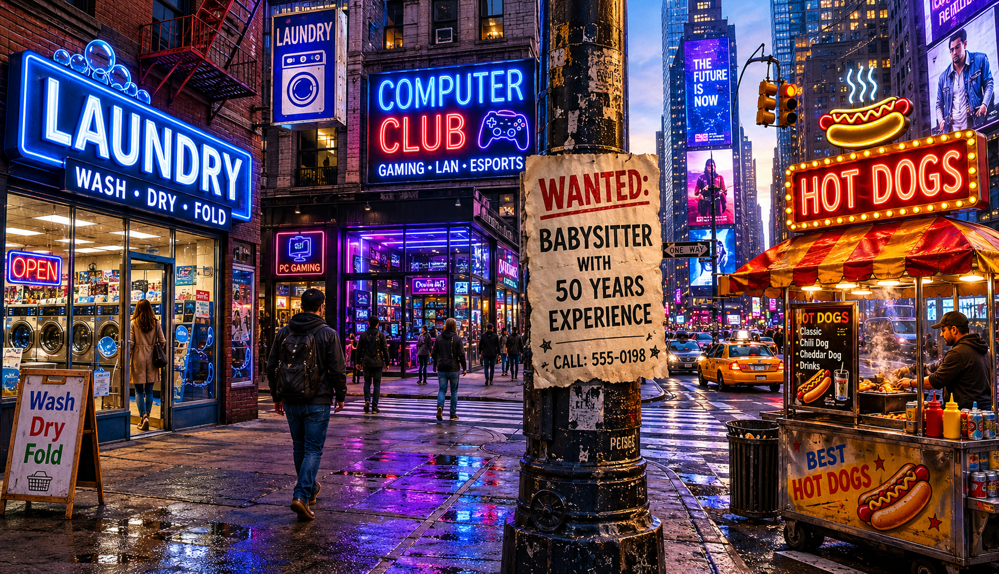

In [8]:
img = Image.open(data_dir / "photo.png")
img

Попробуем расположить перевод текста поверх фотографии. Для этого используем координаты отдельных надписей, которые возвращает сервис OCR. Нам нужно:

1. Получить строки текста и их bounding boxes.
2. Перевести каждую строку.
3. Нарисовать поверх исходного изображения полупрозрачную подложку и русский текст.

Это упрощённый пример визуального перевода. В реальных приложениях приходится аккуратнее подбирать шрифт, размер, переносы и цвет, но общий принцип остаётся тем же.

Для начала извлечём все строки из OCR:

In [9]:
def vertices_to_box(vertices):
    xs = [int(v.get("x", 0)) for v in vertices]
    ys = [int(v.get("y", 0)) for v in vertices]
    return min(xs), min(ys), max(xs), max(ys)

def extract_lines_with_boxes(ocr_result):
    annotation = ocr_result["result"]["textAnnotation"]
    lines = []
    for block in annotation.get("blocks", []):
        for line in block.get("lines", []):
            text = " ".join(word.get("text", "") for word in line.get("words", [])).strip()
            if not text:
                continue
            vertices = line.get("boundingBox", {}).get("vertices", [])
            if vertices:
                box = vertices_to_box(vertices)
            else:
                box = (0, 0, 0, 0)
            lines.append({"text": text, "box": box})
    return lines

photo_ocr = ocr_recognize(img)
photo_lines = extract_lines_with_boxes(photo_ocr)

for item in photo_lines:
    print(item)

{'text': 'F Tra', 'box': (485, 8, 515, 18)}
{'text': 'LAUNDRY', 'box': (433, 29, 555, 80)}
{'text': 'hEN', 'box': (1541, 0, 1592, 47)}
{'text': 'О а', 'box': (496, 89, 523, 102)}
{'text': '| LAUNDRN', 'box': (0, 104, 450, 373)}
{'text': '|', 'box': (565, 111, 623, 186)}
{'text': 'COMPUTER', 'box': (598, 111, 882, 186)}
{'text': 'CLUB', 'box': (617, 188, 782, 253)}
{'text': 'О', 'box': (842, 214, 852, 223)}
{'text': 'THE', 'box': (1140, 96, 1183, 112)}
{'text': 'FUTURE', 'box': (1137, 111, 1211, 137)}
{'text': 'IS', 'box': (1142, 139, 1163, 154)}
{'text': 'NOW', 'box': (1143, 156, 1188, 173)}
{'text': 'NASH • DRY • FOLD', 'box': (110, 269, 383, 384)}
{'text': 'GAMING • LAN • ESPORTS', 'box': (614, 258, 872, 291)}
{'text': 'WANTED:', 'box': (837, 276, 1102, 351)}
{'text': ':', 'box': (1247, 241, 1327, 367)}
{'text': 'HOT DOGS:', 'box': (1286, 241, 1636, 367)}
{'text': '/', 'box': (849, 368, 891, 415)}
{'text': 'BABYSITTER', 'box': (873, 368, 1083, 415)}
{'text': 'jOPEN', 'box': (0, 426, 

Возьмём только тексты, длиннее определённого количества символов, и переведём их:

In [10]:
photo_lines = [item for item in photo_lines if len(item['text'])>7]
texts = [item["text"] for item in photo_lines]
translations = translate_texts(texts, target_language="ru")

for item, translated in zip(photo_lines, translations):
    item["translation"] = translated

photo_lines


[{'text': '| LAUNDRN',
  'box': (0, 104, 450, 373),
  'translation': '| ПРАЧЕЧНАЯ САМООБСЛУЖИВАНИЯ'},
 {'text': 'COMPUTER', 'box': (598, 111, 882, 186), 'translation': 'компьютер'},
 {'text': 'NASH • DRY • FOLD',
  'box': (110, 269, 383, 384),
  'translation': 'НАШИНКОВАТЬ • ВЫСУШИТЬ • СЛОЖИТЬ'},
 {'text': 'GAMING • LAN • ESPORTS',
  'box': (614, 258, 872, 291),
  'translation': 'ИГРЫ • ЛОКАЛЬНАЯ СЕТЬ • КИБЕРСПОРТ'},
 {'text': 'HOT DOGS:',
  'box': (1286, 241, 1636, 367),
  'translation': 'ХОТ-ДОГИ:'},
 {'text': 'BABYSITTER', 'box': (873, 368, 1083, 415), 'translation': 'няня'},
 {'text': 'PC GAMING',
  'box': (450, 438, 529, 449),
  'translation': 'КОМПЬЮТЕРНЫЕ ИГРЫ'},
 {'text': '50 YEARS', 'box': (902, 456, 1073, 496), 'translation': '50 ЛЕТ'},
 {'text': 'EXPERIENCE', 'box': (878, 499, 1086, 549), 'translation': 'опыт'},
 {'text': '• Classic',
  'box': (1312, 543, 1362, 553),
  'translation': '• Классический'},
 {'text': '• Chili Dog',
  'box': (1311, 559, 1373, 576),
  'translation'

Теперь сделаем надписи поверх изображения:

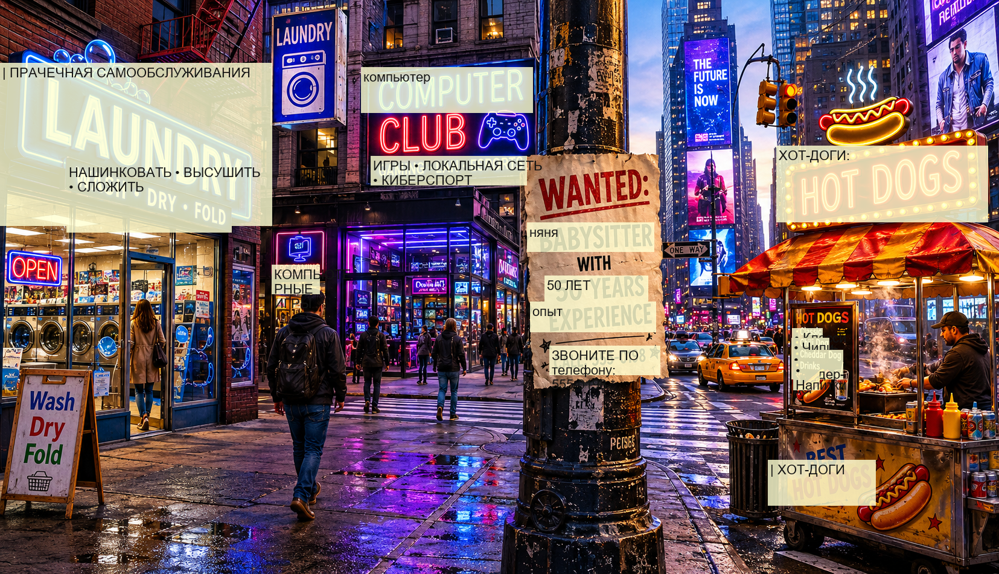

In [11]:
def load_font(size: int):
    candidates = [
        "C:/Windows/Fonts/arial.ttf",
        "C:/Windows/Fonts/segoeui.ttf",
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
    ]
    for candidate in candidates:
        if Path(candidate).exists():
            return ImageFont.truetype(candidate, size=size)
    return ImageFont.load_default()

def draw_translations(img, lines):
    img = img.convert("RGBA")
    overlay = Image.new("RGBA", img.size, (255, 255, 255, 0))
    draw = ImageDraw.Draw(overlay)
    font = load_font(22)
    for item in lines:
        x1, y1, x2, y2 = item["box"]
        text = item.get("translation") or item["text"]
        if x2 <= x1 or y2 <= y1:
            continue
        width = max(80, x2 - x1)
        wrapped = textwrap.fill(text, width=max(8, width // 12))
        draw.rectangle((x1, y1, x2, max(y2, y1 + 48)), fill=(255, 255, 210, 210))
        draw.text((x1 + 4, y1 + 4), wrapped, fill=(20, 20, 20, 255), font=font)
    result = Image.alpha_composite(img, overlay).convert("RGB")
    return result

translated_photo = draw_translations(img,photo_lines)
translated_photo


## Выводы

OCR, VLM и Translate хорошо дополняют друг друга:

* OCR даёт точный текст и координаты.
* VLM помогает понять визуальный контекст, диаграммы и смысл изображения.
* Translate превращает распознанный текст в другой язык.
* PIL позволяет собрать простой прототип визуального перевода прямо в ноутбуке.
